In [14]:
import EFC_learningfMRI.globals as gl
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import os
import EFC_learningfMRI.behaviour as behaviour
import EFC_learningfMRI.vis as vis
from EFC_learningfMRI.util import ttest_im_sess

figDir = gl.figDir

# Behavioural analysis
## Load data

In [15]:
path      = os.path.join(gl.baseDir, 'behavioural')
perf      = pd.read_csv(os.path.join(path, 'behaviour.session.tsv'), sep='\t')
force     = pd.read_csv(os.path.join(path, 'force.session.avg.tsv'), sep='\t')
perf_rep  = pd.read_csv(os.path.join(path, 'behaviour.session.repetition.tsv'), sep='\t')
force_rep = pd.read_csv(os.path.join(path, 'force.session.repetition.avg.tsv'), sep='\t')

# the session tables above are averaged over the five fingers, so the only table left with
# the fingers as a variable -- i.e. the one that still holds the force patterns -- is the long one
force_long = pd.read_csv(os.path.join(path, 'force.trial.long.tsv'), sep='\t')
force_long['finger'] = force_long.finger.str.replace('_raw', '', regex=False)  # melted off the raw columns

print(f'N={perf.subNum.nunique()}')

N=16


## Example trials 
Execution of the same chord (92122) from participant 101 in session 1 and 24.


=== day 1 ===
trialPoint   0.000
MD             NaN
ET             NaN
RT             NaN
        F_avg  F_abs_avg  F_der_abs_avg
thumb    1.01       1.34           2.34
index   -2.20       2.20           3.65
middle   4.93       5.00           5.15
ring    -3.50       3.50          12.81
pinkie  -2.37       2.37           4.24

=== day 24 ===
trialPoint   1.000
MD           0.100
ET           0.066
RT           1.184
        F_avg  F_abs_avg  F_der_abs_avg
thumb    0.13       0.27           1.24
index   -2.87       2.87           1.35
middle   3.53       3.53           3.01
ring    -3.86       3.86           4.01
pinkie  -3.16       3.16           3.08


Text(0.5, 0.98, 'Example trials (force)')

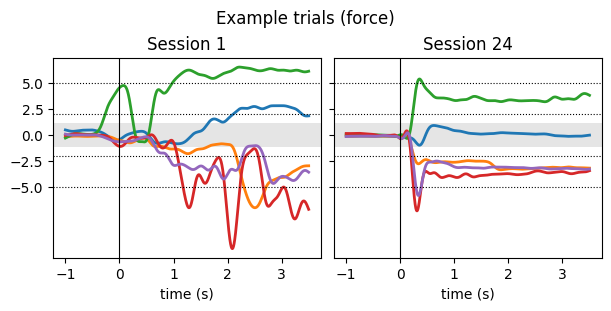

In [16]:
sn = 101
n_block = [1, 1]
sessions  = [1, 24]
n_trial = [12, 15]  # chord 92122

ch_idx = np.array(gl.diffCols)

tAx = np.linspace(-1, 3.5, int(gl.fsample['force'] * 4.5))

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(6, 3), constrained_layout=True,)

for s, sess in enumerate(sessions):
    ax = axs[s]
    filename = os.path.join(gl.baseDir, 'behavioural', f'day{sess}', f'efc4_{sn}_{n_block[s]:02d}.mov')
    mov = behaviour.load_mov(filename)
    mov = mov[mov[:, 0] == n_trial[s]]
    mov = mov[(mov[:, 1] == gl.wait_exec) | (mov[:, 1] == gl.wait_exec - 1)]
    F = mov[:, ch_idx] * gl.fGain
    vis.plot_example_trial(ax, tAx, F, )
    tinfo   = behaviour.analyse_trial(F, chordID=92122)
    scalars = {k: v for k, v in tinfo.items() if np.ndim(v) == 0}
    perFing = {k: v for k, v in tinfo.items() if np.ndim(v) > 0}

    ax.set_title(f'Session {sess}')

    print(f'\n=== day {sess} ===')
    print(pd.Series(scalars).to_string(float_format='{:.3f}'.format))
    print(pd.DataFrame(perFing, index=gl.fingers).round(2).to_string())

fig.suptitle('Example trials (force)')

## Force patterns
Average force pattern of each chord on session 23, taken from `force.trial.long.tsv` — the only behavioural table that keeps the five fingers as a variable rather than averaging over them. Each panel is one chord: the signed force of each finger, averaged over successful trials within a participant and then over participants (error bars are s.e.m. across participants). Every chord is trained in half of the participants and untrained in the other half (8 vs 8), so the two lines are between-participant comparisons of the same physical chord. The grey markers show the instructed direction of each finger (up = extension, down = flexion, nothing = finger not instructed): the measured patterns follow the instruction in every chord, and trained and untrained patterns are hardly distinguishable.

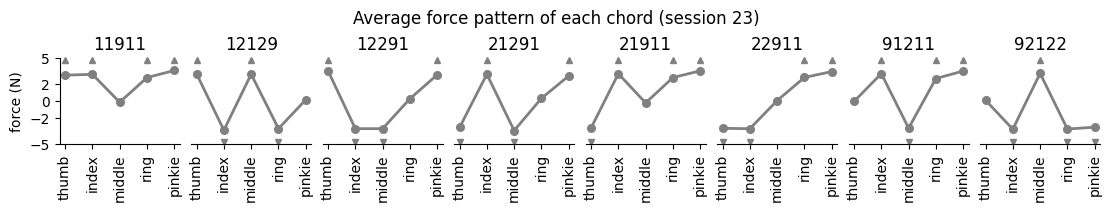

In [17]:
session = 23

# one pattern per participant x chord: successful trials only, as in force.session.avg.tsv
pattern = force_long[(force_long.session == session) & (force_long.trialPoint == 1)]
pattern = pattern.groupby(['subNum', 'chordID', 'finger'], observed=True)[['force_raw']].mean().reset_index()

fig, axs = plt.subplots(1, 8, figsize=(11, 2), sharey=True, constrained_layout=True)
vis.plot_force_pattern(fig, axs, pattern, y='force_raw', color='grey', add_zero=False)
axs[0].set_ylabel('force (N)')
axs[0].set_yticks([-5, -2, 0, 2, 5])
fig.suptitle(f'Average force pattern of each chord (session {session})')

fig.savefig(os.path.join(figDir, 'force_pattern.pdf'))

plt.show()

## Success rate
A trial was considered successful if the participant was able to achieve the instructed chord and hold it for at least 600ms within a 3.5s time-window, and until then end of the trial. Success rate was similar between trained and untrained chords in sessions 3 and 23, and only marginally higher in trained chords on session 9.

 session       A         B         T  dof    p_val          CI95  cohen_d  BF10
       3 trained untrained -1.194764   15 0.250729  [-0.1, 0.03] 0.214437 0.469
       9 trained untrained  1.839564   15 0.085707 [-0.01, 0.09] 0.368657 0.997
      23 trained untrained  1.536348   15 0.145276  [-0.0, 0.03] 0.205738 0.679


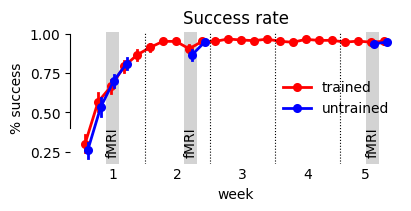

In [18]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.spines['left'].set_bounds(.4, 1)
ax.set_ylabel('% success')
ax.set_title('Success rate')
vis.plot_behav_sess(fig, ax, perf, x='session', y='trialPoint', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'success.pdf'))

ttest = ttest_im_sess(perf[perf.session_type=='scanning'], y='trialPoint', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

## Execution time
Execution time was calculated from the moment the participant exited with any finger from the baseline force range (i.e., ±`gl.thresh`) and the time the instructed fingers entered the target force range (i.e., `gl.ftarget` + 3N). Trained chords were executed significantly faster than untrained chords on sessions 9 and 23.

 session       A         B         T  dof    p_val           CI95  cohen_d    BF10
       3 trained untrained  1.336190   15 0.201405  [-0.04, 0.16] 0.289567   0.542
       9 trained untrained -4.145954   15 0.000862  [-0.3, -0.09] 0.882391  43.477
      23 trained untrained -5.087928   15 0.000134 [-0.34, -0.14] 1.370487 220.906


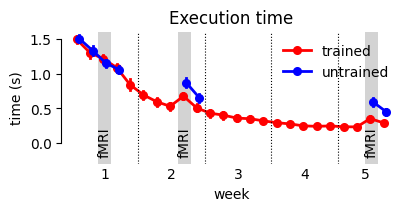

In [19]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((-.3, 1.6))
ax.spines['left'].set_bounds(0, 1.5)
ax.set_ylabel('time (s)')
ax.set_title('Execution time')
vis.plot_behav_sess(fig, ax, perf, x='session', y='ET', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'execution_time.pdf'))

ttest = ttest_im_sess(perf[perf.session.isin(gl.sessions)], y='ET', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

## Mean deviation
Mean deviation was calculated using `EFC_learning.behaviour.calc_MD()` as the average Euclidean distance between the force trajectory in the five-finger space and the straight line joining the force at the beginning and at the end of the execution (i.e., over the same time window used for execution time). Trained chords were executed with significantly smaller deviations than untrained chords on sessions 9 and 23. 

 session       A         B         T  dof    p_val           CI95  cohen_d    BF10
       3 trained untrained -0.256124   15 0.801334  [-0.15, 0.12] 0.052760   0.263
       9 trained untrained -4.274223   15 0.000665 [-0.44, -0.15] 0.872960   54.38
      23 trained untrained -5.229773   15 0.000102 [-0.57, -0.24] 1.216861 280.744


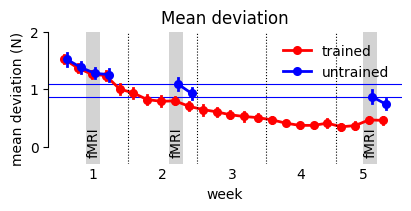

In [20]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((-.3, 2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('mean deviation (N)')
ax.set_title('Mean deviation')
ax.axhline(perf[(perf.chord=='untrained') & (perf.session==9)].MD.mean(), color='b', lw=.8)
ax.axhline(perf[(perf.chord=='untrained') & (perf.session==23)].MD.mean(), color='b', lw=.8)
vis.plot_behav_sess(fig, ax, perf, x='session', y='MD', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'mean_deviation.pdf'))

ttest = ttest_im_sess(perf[perf.session.isin(gl.sessions)], y='MD', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))
plt.show()

## Absolute force
Absolute force was calculated as the average absolute force of each finger, from the moment the participant exited the baseline force range (i.e., ±`gl.fthresh`) until the end of the trial, and was then averaged across the five fingers and across successful trials. Absolute force increased slightly over sessions, but did not differ significantly between trained and untrained chords in any of the scanning sessions.

 session       A         B         T  dof    p_val          CI95  cohen_d  BF10
       3 trained untrained -0.192669   15 0.849802 [-0.05, 0.05] 0.022645  0.26
       9 trained untrained  1.666232   15 0.116407 [-0.01, 0.08] 0.211804 0.796
      23 trained untrained  0.693541   15 0.498570 [-0.03, 0.06] 0.102358 0.315


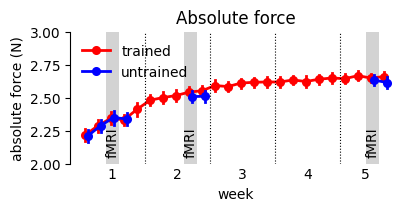

In [21]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((2, 3))
ax.spines['left'].set_bounds(2, 3)
ax.set_ylabel('absolute force (N)')
ax.set_title('Absolute force')
vis.plot_behav_sess(fig, ax, force, x='session', y='force_abs', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])
ax.legend(loc='upper left', frameon=False)
fig.savefig(os.path.join(figDir, 'force_abs.pdf'))
ttest = ttest_im_sess(force[force.session.isin(gl.sessions)], y='force_abs', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

## Mean force derivative
The force derivative was calculated as the average absolute first derivative of the force of each finger, over the same time window used for absolute force, and was then averaged across the five fingers and across successful trials. Trained chords were produced with a significantly lower force derivative than untrained chords on sessions 9 and 23.

 session       A         B         T  dof    p_val           CI95  cohen_d   BF10
       3 trained untrained  0.666834   15 0.515005  [-0.07, 0.13] 0.079443  0.311
       9 trained untrained -4.213709   15 0.000752 [-0.25, -0.08] 0.531242 48.934
      23 trained untrained -3.679242   15 0.002232  [-0.3, -0.08] 0.588636 19.241


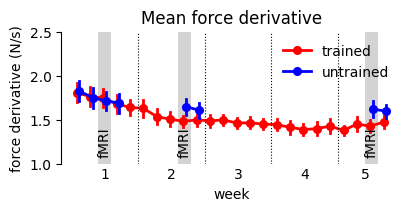

In [22]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((1, 2.5))
ax.spines['left'].set_bounds(1, 2.5)
ax.set_ylabel('force derivative (N/s)')
ax.set_title('Mean force derivative')
vis.plot_behav_sess(fig, ax, force, x='session', y='force_der', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])
ax.legend(loc='upper right', frameon=False)
fig.savefig(os.path.join(figDir, 'force_der.pdf'))
ttest = ttest_im_sess(force[force.session.isin(gl.sessions)], y='force_der', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

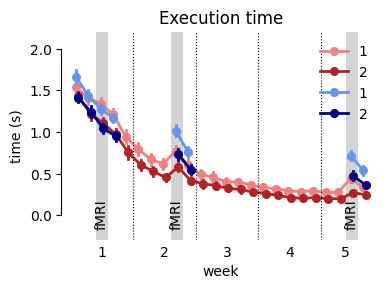

In [23]:
fig, ax = plt.subplots(figsize=(4,3),)
ax.set_ylim((-.3, 2.2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('time (s)')
ax.set_title('Execution time')
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='trained'], x='session', y='ET', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='untrained'], x='session', y='ET', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_execution_time.pdf'))
plt.show()

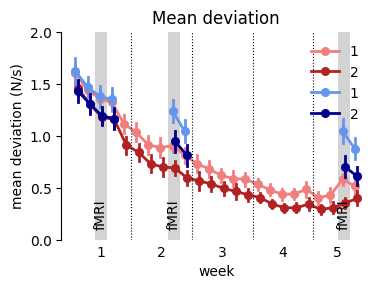

In [24]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((0, 2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('mean deviation (N/s)')
ax.set_title('Mean deviation')
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='trained'], x='session', y='MD', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='untrained'], x='session', y='MD', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_mean_deviation.pdf'))
plt.show()

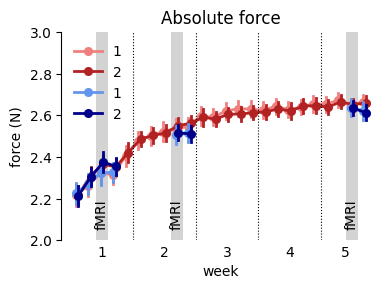

In [25]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((2, 3))
ax.spines['left'].set_bounds(2, 3)
ax.set_ylabel('force (N)')
ax.set_title('Absolute force')
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='trained'], x='session', y='force_abs', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='untrained'], x='session', y='force_abs', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='best', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_force_absolute.pdf'))
plt.show()

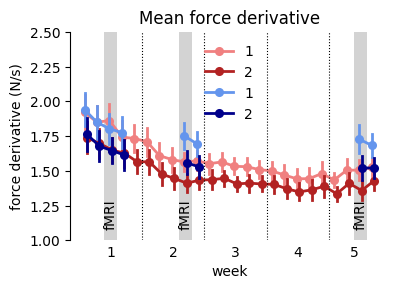

In [26]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((1, 2.5))
ax.spines['left'].set_bounds(1, 2.5)
ax.set_ylabel('force derivative (N/s)')
ax.set_title('Mean force derivative')
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='trained'], x='session', y='force_der', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='untrained'], x='session', y='force_der', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_force_derivative.pdf'))
plt.show()